# Steam Analyzer

This project aims to analyze trends in Steams discount strategy and predict price on games in the future based on it.

[Dataset](https://www.kaggle.com/datasets/benjaminlundkvist/steam-sales-historical-dataset)


# Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

# Data preparation

In [3]:
df = pd.read_csv("data/steam_prices.csv", parse_dates=["month"])

# discount percentage
df["discount_percent"] = (1 - df["lowest_price"] / df["base_price"]) * 100

monthly = df.groupby("month").agg(
    avg_discount=("discount_percent", "mean"),
    avg_days_on_sale=("days_on_sale", "mean")
).reset_index()

monthly.head()

,month,avg_discount,avg_days_on_sale
0,2023-10-01,50.025013,4.000000
1,2023-11-01,52.810837,9.179211
2,2023-12-01,54.649307,10.812057
3,2024-01-01,54.003321,4.992982
4,2024-02-01,32.035262,2.861111


# Data Visualisation

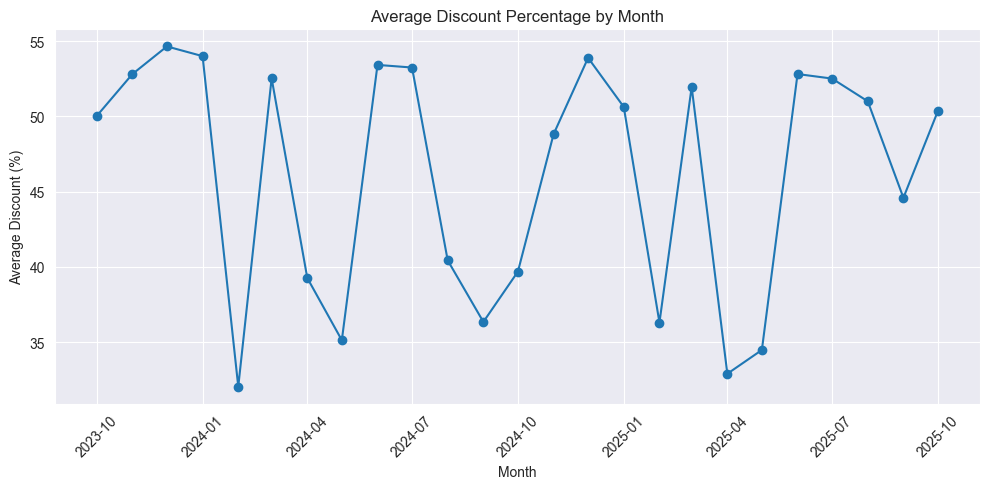

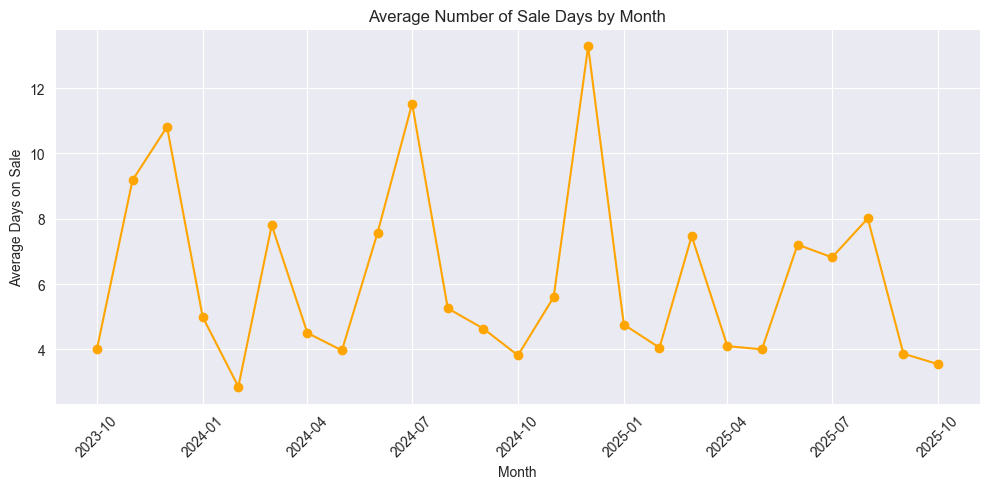

In [4]:
# --- Plot 1: Average discount percentage per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_discount"], marker="o")
plt.title("Average Discount Percentage by Month")
plt.xlabel("Month")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 2: Average number of sale days per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_days_on_sale"], marker="o", color="orange")
plt.title("Average Number of Sale Days by Month")
plt.xlabel("Month")
plt.ylabel("Average Days on Sale")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The two graphs show a clear positive correlation — months with higher average discounts also tend to have more sale days.
This suggests that major seasonal sales drive both deeper and longer discounts across the platform.

According to these graphs, highest discounts are mostly common in times of major sales,
For example winter 2023-2024 and early autumn 2024 have discounts up to 55%. Its the same for summer 2024 and winter 2024-2025.


The graph also shows, that summer sale 2025 was somewhat short, compared to other years. That suggests, that future user recommendations better include timeperiod instead of just season

Also, October 2025 seems to have low amount of days per sale, however discount reaches over 50%, which is strange.

This anomaly in October 2025 is likely explained by short but major promotions — for example, Space Marine 2 (-50%), Darktide (-60%), and Hunt: Showdown (-60%) all had discounts between late September and early October. These brief yet high-impact sales caused a spike in average discount percentage despite the low number of sale days.

# Season sales heatmap

Due to lack of full information regarding 2023 and 2025, comparison of all three of them is not possible, but its possible to compare those years with 2024

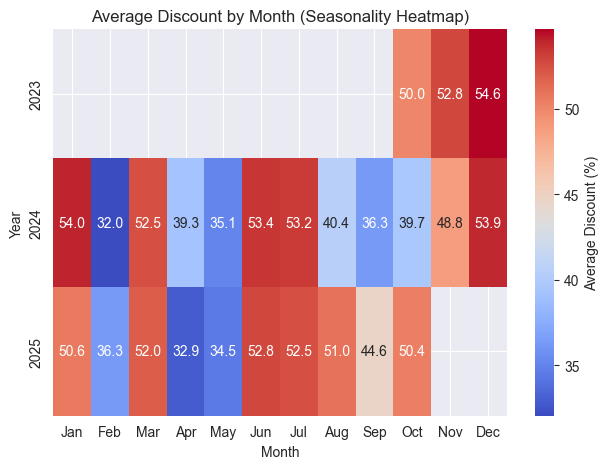

In [5]:
pivot = (
    df.assign(
        year=df['month'].dt.year,
        month_name=df['month'].dt.strftime('%b')
    )
    .groupby(['year', 'month_name'])['discount_percent']
    .mean()
    .unstack()
    .reindex(columns=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
)

sns.heatmap(pivot, cmap="coolwarm", annot=True, fmt=".1f", cbar_kws={'label': 'Average Discount (%)'})
plt.title("Average Discount by Month (Seasonality Heatmap)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


its clearly seen: mostly discounts are the same, with small errors up to 3.5 procents. However, late summer and early autumn sales in 2025 (and 2023 in case of october) are 10% higher compared to 2024

However, april 2024 is 6% higher than april 2025. It may add some noise

# Distribution of discounts

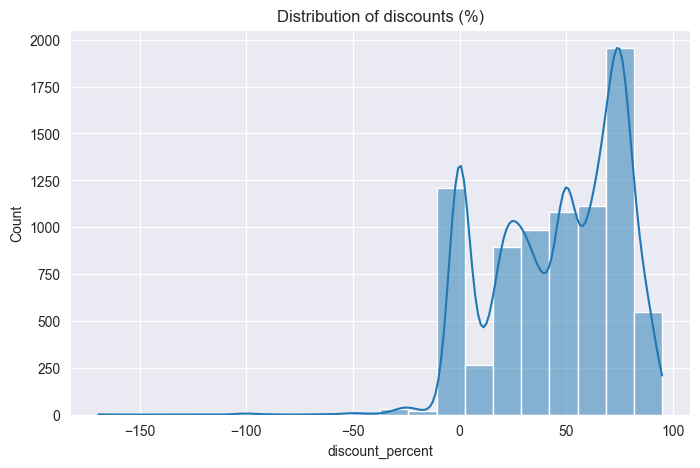

In [6]:
plt.figure(figsize=(8,5))
sns.histplot(df['discount_percent'], bins=20, kde=True)
plt.title("Distribution of discounts (%)")
plt.show()

Most games receive moderate to high discounts, especially around 50–80%. The data confirms that heavy discounts are quite common, possibly due to regular store-wide sales or frequent price adjustments.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df['month_num'] = df['month'].dt.month
df['year'] = df['month'].dt.year

features = [
    'base_price', 'price_changes', 'days_on_sale',
    'month_num', 'year'
]
X = df[features]
y = df['discount_percent']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MAE: 15.496177019085485
R²: 0.48133093740847044


In [8]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

df = df.sort_values('month')

X = df[features]
y = df['discount_percent']

tscv = TimeSeriesSplit(n_splits=5)

mae_list = []
r2_list = []

for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = RandomForestRegressor(n_estimators=200, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae_list.append(mean_absolute_error(y_test, y_pred))
    r2_list.append(r2_score(y_test, y_pred))

print("Average MAE:", np.mean(mae_list))
print("Average R²:", np.mean(r2_list))


Average MAE: 16.620601799958386
Average R²: 0.39208707570747603


In [9]:
sale_periods = {
    'autumn_sale': [('2024-11-27', '2024-12-04')],
    'winter_sale': [('2024-12-19', '2025-01-02')],
    'spring_sale': [('2025-03-13', '2025-03-20')],
    'summer_sale': [('2025-06-26', '2025-07-10')],
}

def is_in_sale(date, sale_periods):
    for sale, periods in sale_periods.items():
        for start, end in periods:
            start_date = pd.to_datetime(start)
            end_date = pd.to_datetime(end)
            if start_date <= date <= end_date:
                return 1
    return 0

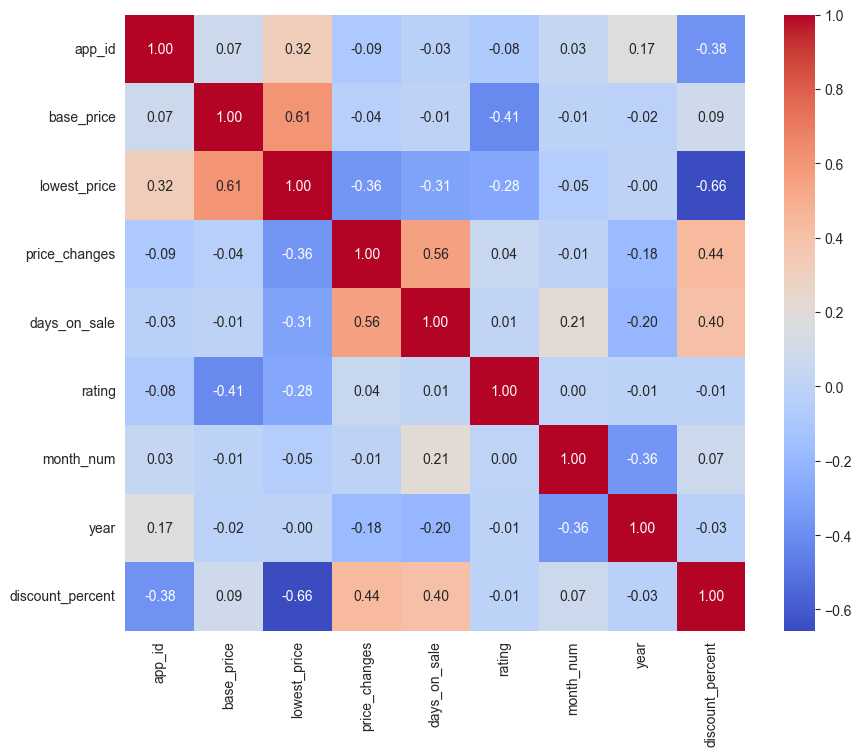

In [15]:
df['discount_percent'] = pd.to_numeric(df['discount_percent'], errors='coerce')

cols = [col for col in df.columns if col != 'discount_percent']
df = df[cols + ['discount_percent']]

numeric_df = df.select_dtypes(include=['number'])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.show()